# 가속도 기반 동작 분류 — 1D CNN

## 1. 프로젝트 목적과 분석 범위

**목적:** 석사 연구의 T6 3축 가속도로 하강 전·하강 시작·착지 반응을 구분할 수 있는지 확인.

- **입력:** 확정 이벤트 경계에서 추출한 1초 윈도우
- **평가:** 참가자 단위 Train/Val/Test 분할
- **비교:** Global z-score vs. Window mean-centering + Train 축별 표준편차
- **설정:** 소규모 CNN 구조 유지, 하이퍼파라미터 튜닝 미수행
- **해석 범위:** 확정 경계 기반 구간 분류. Test는 기존 대상의 탐색적 재평가

### 주요 결과

| 항목 | 결과 |
|---|---:|
| Global z-score Val Macro F1 | 0.3330 |
| Mean-centered Val Accuracy / Macro F1 | 1.0000 / 1.0000 |
| Mean-centered 선택 epoch / Val loss | 56 / 0.0041 |
| 학습 종료 epoch | 68 |
| Test Accuracy / Macro F1 | 0.9630 / 0.9630 |
| Test 오답 | 5 / 135 윈도우 |


### 공개 자료 안내

참가자 ID와 개인 경로는 가명 처리했으며, 코드와 저장된 실행 결과를 공개합니다.

원데이터·경계 CSV·전용 로더·checkpoint는 포함하지 않아, 공개 파일만으로 전체 재실행은 불가능합니다. 자세한 실행 조건은 README를 참고해 주세요.


In [1]:
# 실행 셀 01
# 라이브러리 및 안전한 표 출력 함수
from IPython.display import display as notebook_display

from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


In [2]:
# 실행 셀 02
# Seed와 프로젝트 경로 설정

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

import os

# 별도 준비한 가명 처리 데이터의 루트. 공개 패키지에는 포함하지 않습니다.
PROJECT_DIR = Path(os.environ.get("T6_PROJECT_DIR", "./private_data")).resolve()

BOUNDARY_PATH = (
    PROJECT_DIR
    / "outputs"
    / "t6_descent_candidates_v2"
    / "manual_review_resolved_v1"
    / "final_descent_boundaries_178.csv"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("프로젝트 폴더:", PROJECT_DIR.exists())
print("하강 경계 파일:", BOUNDARY_PATH.exists())
print("학습 장치:", device)


프로젝트 폴더: True
하강 경계 파일: True
학습 장치: cpu


## 2. Data & QC

참가자 15명의 데이터를 Train 9명, Val 3명, Test 3명으로 나눴습니다. 같은 참가자의 데이터는 하나의 그룹에만 포함해, 학습에서 본 참가자가 평가에 다시 등장하지 않도록 했습니다.

신호 품질과 동작 경계를 검토하고, 세 구간에서 각각 1초를 확보할 수 있는 trial을 분석에 사용했습니다.

| 검토 단계 | Train trial | Val trial |
|---|---:|---:|
| 제외 전 | 135 | 45 |
| 신호 품질 검토 후 | 135 | 44 |
| 동작 경계 검토 후 | 134 | 44 |
| 1초 구간 확보 여부 확인 후 | **132** | **44** |

제외한 데이터와 사유는 다음과 같습니다.

- **신호 품질:** `P05__83cm__R3` — 심한 freeze와 clipping으로 제외했습니다. 이 결정은 참가자 분할 전에 반영했습니다.
- **동작 경계:** `P01__103cm__R4` — 하강 종료 후보가 두 개여서 경계를 하나로 확정하지 못해 제외했습니다.
- **구간 길이:** `P02__83cm__R1`, `P03__83cm__R4` — 하강 종료 후 1초를 확보하지 못해 제외했습니다.

Test는 기존 QC 검토와 승인 기록을 반영한 **45 trial**을 사용했습니다. 짧은 Z축 clipping이 있었지만 수동 검토에서 사용을 승인한 1건이 포함되어 있습니다.

QC와 경계 검토는 앞선 분석에서 진행했습니다. 이 노트북에서는 확정된 경계표를 불러와 1초 구간을 추출할 수 있는지 다시 확인합니다.

In [3]:
# 실행 셀 03
# 확정된 Train/Val 경계표
boundaries = pd.read_csv(BOUNDARY_PATH)
notebook_display(boundaries.groupby("split").agg(
    trials=("sample_id", "size"), participants=("person", "nunique")
).reindex(["Train", "Val"]))


,trials,participants
split,,
Train,134,9
Val,44,3


In [4]:
# 실행 셀 04
# 1초 구간 확보 및 Train/Val 구성 검증

CONTEXT_SECONDS = 1.0

metadata = boundaries.copy()

assert metadata["sample_id"].is_unique, "중복 trial ID가 있습니다."
assert set(metadata["split"]) == {"Train", "Val"}, "분할 구성을 확인하세요."

time_columns = ["record_begin_s", "start_s", "end_s", "record_end_s"]
assert np.isfinite(metadata[time_columns].to_numpy(dtype=float)).all(), \
    "시간 정보에 결측 또는 무한값이 있습니다."

valid_boundaries = (
    (metadata["record_begin_s"] <= metadata["start_s"])
    & (metadata["start_s"] < metadata["end_s"])
    & (metadata["end_s"] <= metadata["record_end_s"])
)
assert valid_boundaries.all(), "기록 범위를 벗어난 경계가 있습니다."

# 이전 2초/1.5초 설정과 구분되는 새 추출 범위
metadata["pre_start_s"] = metadata["start_s"] - CONTEXT_SECONDS
metadata["pre_end_s"] = metadata["start_s"]
metadata["post_start_s"] = metadata["end_s"]
metadata["post_end_s"] = metadata["end_s"] + CONTEXT_SECONDS

eligible = (
    (metadata["pre_start_s"] >= metadata["record_begin_s"])
    & (metadata["post_end_s"] <= metadata["record_end_s"])
    & (metadata["end_s"] - metadata["start_s"] >= CONTEXT_SECONDS)
)

excluded_metadata = metadata.loc[~eligible].copy()
selected_metadata = metadata.loc[eligible].copy().reset_index(drop=True)

# 선별 전후 모두 피험자 독립 분할 유지
assert metadata.groupby("person")["split"].nunique().eq(1).all(), \
    "동일 피험자가 여러 split에 포함되어 있습니다."

summary = (
    selected_metadata.groupby("split")
    .agg(trials=("sample_id", "size"), participants=("person", "nunique"))
    .reindex(["Train", "Val"])
)

assert summary["trials"].to_dict() == {"Train": 132, "Val": 44}, \
    "예상 trial 수와 다릅니다. 선별 결과를 확인하세요."

notebook_display(summary)

print("길이 조건 미충족 trial:")
notebook_display(
    excluded_metadata[
        ["sample_id", "split", "record_begin_s",
         "start_s", "end_s", "record_end_s"]
    ]
)


,trials,participants
split,,
Train,132,9
Val,44,3


길이 조건 미충족 trial:


,sample_id,split,record_begin_s,start_s,end_s,record_end_s
14,P02__83cm__R1,Train,0.0,3.517333,10.387333,10.62
32,P03__83cm__R4,Train,0.0,2.668667,8.685333,9.12


In [5]:
# 실행 셀 05
# Trial 폴더 경로 연결 및 파일 존재 확인

RECORDS_DIR = PROJECT_DIR / "persons"

selected_metadata["record_path"] = selected_metadata.apply(
    lambda row: (
        RECORDS_DIR
        / row["person"]
        / "records"
        / row["record_folder"]
    ),
    axis=1,
)

selected_metadata["record_exists"] = selected_metadata["record_path"].map(
    Path.exists
)

missing_records = selected_metadata.loc[
    ~selected_metadata["record_exists"],
    ["sample_id", "record_path"],
]

assert missing_records.empty, (
    f"찾을 수 없는 trial 폴더가 {len(missing_records)}개 있습니다."
)

print("사용 trial 수:", len(selected_metadata))
print("확인된 trial 폴더:", selected_metadata["record_exists"].sum())


사용 trial 수: 176
확인된 trial 폴더: 176


In [6]:
# 실행 셀 06
# 검증된 신호 로딩 함수 연결

import sys

project_path = str(PROJECT_DIR)

if project_path not in sys.path:
    sys.path.insert(0, project_path)

from analyze_mvic import (
    parse_channels,
    parse_atom_duration,
    load_signal,
)

print("신호 로딩 함수 연결 완료")


신호 로딩 함수 연결 완료


## 3. Window Definition

실험 비디오와 가속도 파형을 함께 보며 하강 시작과 종료 시점을 확정했습니다. 이 시점을 기준으로 하강 전·하강 시작·착지 반응을 각각 1초씩 추출했습니다.

하강 구간은 정지 상태에서 움직임으로 전환되는 패턴을 보기 위해 시작 직후 1초를 사용했습니다.

| 라벨 | 동작 구간 | 추출 범위 |
|---:|---|---|
| 0 | PRE_DESCENT — 하강 전 | 하강 시작 직전 1초 |
| 1 | DESCENT — 하강 시작 | 하강 시작 직후 1초 |
| 2 | LANDING_RESPONSE — 착지 반응 | 하강 종료 직후 1초 |

각 구간은 1,500 Hz로 측정한 XYZ 가속도 1초 분량이며, 모델에는 **(3, 1500)** 형태로 입력했습니다.

trial당 세 구간을 추출해 **Train 396개, Val 132개, Test 135개 윈도우**를 구성했습니다. 같은 trial에서 추출한 윈도우는 동일한 데이터 분할에 유지했습니다.

In [7]:
# 실행 셀 07
# 예시 trial의 가속도 채널과 샘플링 주파수 확인

example_row = selected_metadata.iloc[0]
example_record = Path(example_row["record_path"])

contents_candidates = [
    path
    for path in example_record.iterdir()
    if path.name.lower() == "contents"
]

assert len(contents_candidates) == 1, (
    f"contents 파일을 {len(contents_candidates)}개 찾았습니다."
)

contents_path = contents_candidates[0]
channels = parse_channels(contents_path)

atom_duration = parse_atom_duration(contents_path)
sampling_rate = 1.0 / atom_duration

keywords = ("ACC", "ACCEL", "24G")

acceleration_channels = [
    channel
    for channel in channels
    if any(
        keyword in f"{channel.name} {channel.kind}".upper()
        for keyword in keywords
    )
]

print("예시 trial:", example_row["sample_id"])
print(f"샘플링 주파수: {sampling_rate:.1f} Hz")
print(f"가속도 후보 채널 수: {len(acceleration_channels)}")
print("\n가속도 후보 채널:")

for channel in acceleration_channels:
    print(f"- {channel.name} | type={channel.kind}")


예시 trial: P01__83cm__R1
샘플링 주파수: 1500.0 Hz
가속도 후보 채널 수: 6

가속도 후보 채널:
- DTS-ACCELEROMETER 16G-x | type=dts_accel_16
- DTS-ACCELEROMETER 16G-y | type=dts_accel_16
- DTS-ACCELEROMETER 16G-z | type=dts_accel_16
- DTS-ACCELEROMETER 24G-x | type=dts_accel_24
- DTS-ACCELEROMETER 24G-y | type=dts_accel_24
- DTS-ACCELEROMETER 24G-z | type=dts_accel_24


In [8]:
# 실행 셀 08
# T6 24G XYZ 신호 로더 정의 및 단일 trial 검증

T6_CHANNEL_TYPE = "dts_accel_24"
EXPECTED_SAMPLING_RATE = 1500.0


def load_t6_xyz(record_dir):
    """한 trial에서 T6 24G의 X/Y/Z 신호를 불러온다."""

    record_dir = Path(record_dir)
    contents_path = record_dir / "contents"

    if not contents_path.exists():
        raise FileNotFoundError(f"contents 파일이 없습니다: {record_dir}")

    channels = parse_channels(contents_path)

    axis_channels = {}

    for axis in ("x", "y", "z"):
        matches = [
            channel
            for channel in channels
            if (
                channel.kind == T6_CHANNEL_TYPE
                and channel.name.lower().endswith(f"-{axis}")
            )
        ]

        if len(matches) != 1:
            raise ValueError(
                f"{axis.upper()}축 채널이 {len(matches)}개입니다: {record_dir}"
            )

        axis_channels[axis] = matches[0]

    signals = []

    for axis in ("x", "y", "z"):
        archive = axis_channels[axis].raw

        if archive is None:
            raise ValueError(
                f"{axis.upper()}축 raw archive가 없습니다: {record_dir}"
            )

        signals.append(load_signal(record_dir, archive))

    lengths = [len(signal) for signal in signals]

    if len(set(lengths)) != 1:
        raise ValueError(f"XYZ 신호 길이가 다릅니다: {lengths}")

    xyz = np.stack(signals, axis=0)

    atom_duration = parse_atom_duration(contents_path)
    sampling_rate = 1.0 / atom_duration

    if not np.isclose(sampling_rate, EXPECTED_SAMPLING_RATE):
        raise ValueError(
            f"예상하지 못한 샘플링 주파수입니다: {sampling_rate:.3f} Hz"
        )

    if not np.isfinite(xyz).all():
        raise ValueError(f"신호에 결측 또는 무한값이 있습니다: {record_dir}")

    units = axis_channels["x"].raw.units

    return xyz, sampling_rate, units


example_xyz, example_fs, example_units = load_t6_xyz(example_record)

print("신호 shape:", example_xyz.shape)
print(f"샘플링 주파수: {example_fs:.1f} Hz")
print("단위:", example_units)
print("축별 최솟값:", example_xyz.min(axis=1))
print("축별 최댓값:", example_xyz.max(axis=1))


신호 shape: (3, 14184)
샘플링 주파수: 1500.0 Hz
단위: 
축별 최솟값: [-0.31036118  0.         -0.12267066]
축별 최댓값: [0.34057618 2.12310797 0.67749024]


In [9]:
# 실행 셀 09
# 단일 trial의 3개 동작 구간 추출

WINDOW_SECONDS = 1.0
WINDOW_SAMPLES = int(WINDOW_SECONDS * EXPECTED_SAMPLING_RATE)

PHASE_NAMES = {
    0: "PRE_DESCENT",
    1: "DESCENT",
    2: "LANDING_RESPONSE",
}


def extract_phase_windows(row):
    """확정 경계를 기준으로 3개의 1초 window를 추출한다."""

    xyz, sampling_rate, _ = load_t6_xyz(row["record_path"])

    record_begin = float(row["record_begin_s"])
    descent_start = float(row["start_s"])
    descent_end = float(row["end_s"])

    # onset_v3: 하강 시작 직후 1초를 사용

    window_start_times = {
        0: descent_start - WINDOW_SECONDS,
        1: descent_start,
        2: descent_end,
    }

    windows = {}

    for label, start_time in window_start_times.items():
        start_index = int(
            round((start_time - record_begin) * sampling_rate)
        )
        end_index = start_index + WINDOW_SAMPLES

        if start_index < 0 or end_index > xyz.shape[1]:
            raise ValueError(
                f"{PHASE_NAMES[label]} 범위가 신호를 벗어납니다: "
                f"{row['sample_id']}"
            )

        window = xyz[:, start_index:end_index]

        if window.shape != (3, WINDOW_SAMPLES):
            raise ValueError(
                f"예상하지 못한 window shape입니다: {window.shape}"
            )

        windows[label] = window

    return windows


example_windows = extract_phase_windows(example_row)

for label, window in example_windows.items():
    print(f"{PHASE_NAMES[label]:<18} shape: {window.shape}")
print("onset_v3 입력: PRE [S-1, S), DESCENT [S, S+1), LANDING [E, E+1)")


PRE_DESCENT        shape: (3, 1500)
DESCENT            shape: (3, 1500)
LANDING_RESPONSE   shape: (3, 1500)
onset_v3 입력: PRE [S-1, S), DESCENT [S, S+1), LANDING [E, E+1)


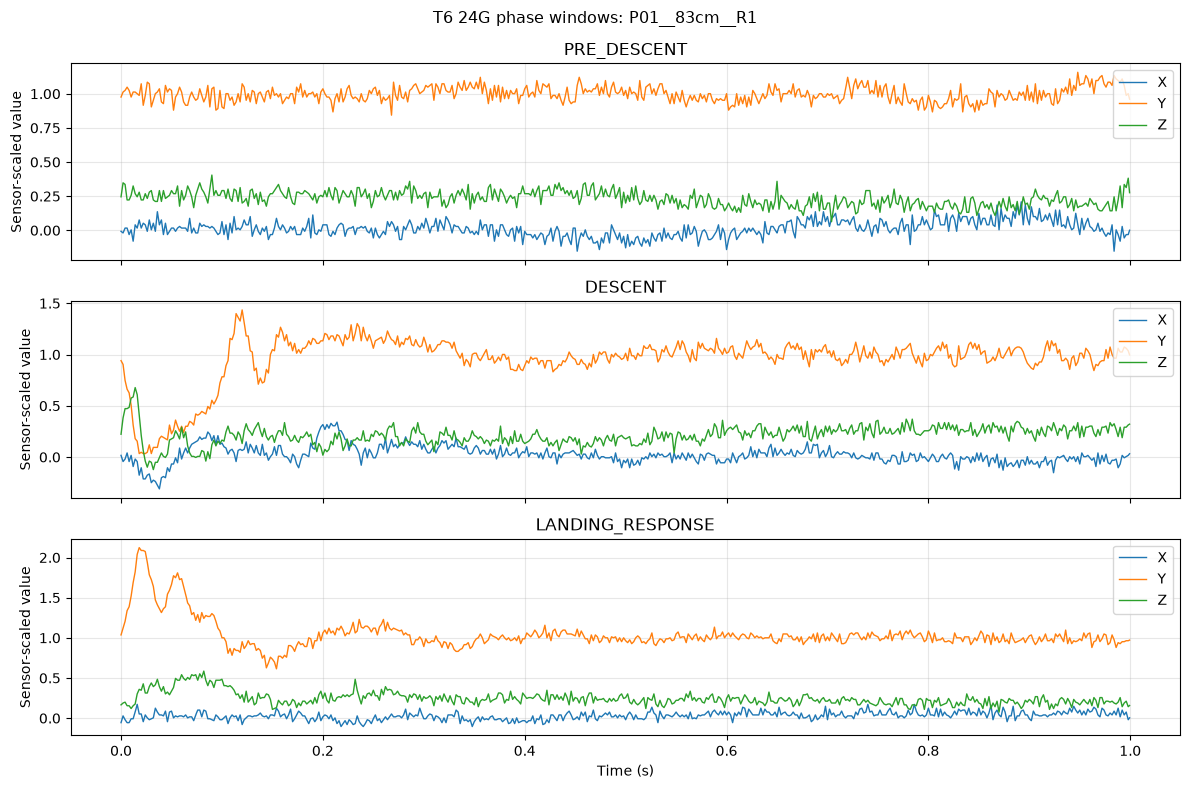

In [10]:
# 실행 셀 10
# 예시 trial의 단계별 T6 XYZ 파형 확인

time_axis = np.arange(WINDOW_SAMPLES) / example_fs
axis_names = ("X", "Y", "Z")
axis_colors = ("tab:blue", "tab:orange", "tab:green")

fig, plot_axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
)

for plot_axis, (label, window) in zip(
    plot_axes,
    example_windows.items(),
):
    for axis_index, (axis_name, color) in enumerate(
        zip(axis_names, axis_colors)
    ):
        plot_axis.plot(
            time_axis,
            window[axis_index],
            label=axis_name,
            color=color,
            linewidth=1.0,
        )

    plot_axis.set_title(PHASE_NAMES[label])
    plot_axis.set_ylabel("Sensor-scaled value")
    plot_axis.grid(alpha=0.3)
    plot_axis.legend(loc="upper right")

plot_axes[-1].set_xlabel("Time (s)")

fig.suptitle(
    f"T6 24G phase windows: {example_row['sample_id']}",
    fontsize=13,
)

plt.tight_layout()
plt.show()


In [11]:
# 실행 셀 11
# Train/Val 전체 phase dataset 구축

all_windows = []
all_labels = []
window_records = []

for _, row in selected_metadata.iterrows():
    phase_windows = extract_phase_windows(row)

    for label in (0, 1, 2):
        all_windows.append(
            phase_windows[label].astype(np.float32)
        )
        all_labels.append(label)

        window_records.append({
            "sample_id": row["sample_id"],
            "person": row["person"],
            "split": row["split"],
            "label": label,
            "phase": PHASE_NAMES[label],
        })

X_all = np.stack(all_windows)
y_all = np.asarray(all_labels, dtype=np.int64)
window_metadata = pd.DataFrame(window_records)

train_mask = window_metadata["split"].eq("Train").to_numpy()
val_mask = window_metadata["split"].eq("Val").to_numpy()

X_train_raw = X_all[train_mask]
y_train = y_all[train_mask]

X_val_raw = X_all[val_mask]
y_val = y_all[val_mask]

assert X_train_raw.shape == (396, 3, 1500)
assert X_val_raw.shape == (132, 3, 1500)

print("Train shape:", X_train_raw.shape)
print("Val shape:  ", X_val_raw.shape)

notebook_display(
    pd.crosstab(
        window_metadata["split"],
        window_metadata["phase"],
    ).reindex(["Train", "Val"])
)


Train shape: (396, 3, 1500)
Val shape:   (132, 3, 1500)


phase,DESCENT,LANDING_RESPONSE,PRE_DESCENT
split,,,
Train,132,132,132
Val,44,44,44


## 4. Model & Training

두 개의 합성곱층으로 구성한 소규모 1D CNN을 사용했습니다. 모델 구조와 학습 설정을 유지한 채 전처리 두 가지를 비교했습니다.

| 항목 | 설정 |
|---|---|
| Conv1 | Conv1d 3→16, kernel 15, padding 7 |
| Conv2 | Conv1d 16→32, kernel 7, padding 3 |
| Activation / Pooling | 각 합성곱 뒤 ReLU → MaxPool1d(4) |
| Global Average Pooling | AdaptiveAvgPool1d(1) |
| Classifier | Linear(32, 3) |
| Trainable parameters | 4,451 |
| Batch size / Loss | 32 / CrossEntropyLoss |
| Optimizer / Learning rate | Adam / 0.001 |
| Max epochs | 100 |
| Early stopping | Val loss 기준, patience 12, min_delta 0.0001 |

Train에서 가중치와 편향을 학습하고, 매 epoch 종료 후 Val을 평가했습니다. Val loss가 최소 개선폭보다 크게 감소하면 모델을 저장하고, 12 epoch 동안 개선되지 않으면 학습을 종료했습니다.

하이퍼파라미터 튜닝은 수행하지 않았습니다. 두 실험의 초기 가중치가 동일했음을 보장하지 않으므로, 전처리에 따른 성능 차이를 탐색한 결과로 해석했습니다.

## 5. Preprocessing

윈도우마다 다른 평균 수준을 제거했을 때 분류 성능이 달라지는지 확인하기 위해, 두 전처리 방식을 비교했습니다.

| 방식 | 평균 제거 기준 | 스케일링 기준 |
|---|---|---|
| Global z-score | Train 전체의 축별 평균 | Train 전체의 축별 표준편차 |
| Window mean-centering | 각 윈도우의 축별 평균 | 평균 제거된 Train 전체의 축별 표준편차 |

두 방식은 원신호에 각각 적용했습니다. Val/Test에도 Train에서 구한 정규화 기준값을 사용했으며, Window mean-centering의 윈도우별 평균은 각 입력에서 계산했습니다.

### 5-1. Global z-score

In [12]:
# 실행 셀 12
# Train 기준 축별 z-score 정규화

train_mean = X_train_raw.mean(
    axis=(0, 2),
    keepdims=True,
)

train_std = X_train_raw.std(
    axis=(0, 2),
    keepdims=True,
)

assert np.all(train_std > 0), \
    "표준편차가 0인 축이 있습니다."

X_train = (
    (X_train_raw - train_mean) / train_std
).astype(np.float32)

X_val = (
    (X_val_raw - train_mean) / train_std
).astype(np.float32)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

normalization_summary = pd.DataFrame({
    "axis": ["X", "Y", "Z"],
    "train_mean": train_mean.reshape(-1),
    "train_std": train_std.reshape(-1),
})

notebook_display(normalization_summary)

print(
    "정규화 후 Train 축별 평균:",
    X_train.mean(axis=(0, 2)),
)
print(
    "정규화 후 Train 축별 표준편차:",
    X_train.std(axis=(0, 2)),
)


,axis,train_mean,train_std
0,X,-0.054152,0.078303
1,Y,0.887376,0.340715
2,Z,0.163769,0.183141


정규화 후 Train 축별 평균: [-3.6271736e-08  9.1244473e-08  3.2161623e-07]
정규화 후 Train 축별 표준편차: [0.9999998 0.9999999 1.       ]


In [13]:
# 실행 셀 13
# PyTorch Dataset과 DataLoader 구성

BATCH_SIZE = 32

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train),
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val),
)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

X_batch, y_batch = next(iter(train_loader))

print("Train dataset:", len(train_dataset))
print("Val dataset:  ", len(val_dataset))
print("Batch X shape: ", X_batch.shape)
print("Batch y shape: ", y_batch.shape)
print("Batch X dtype: ", X_batch.dtype)
print("Batch y dtype: ", y_batch.dtype)


Train dataset: 396
Val dataset:   132
Batch X shape:  torch.Size([32, 3, 1500])
Batch y shape:  torch.Size([32])
Batch X dtype:  torch.float32
Batch y dtype:  torch.int64


In [14]:
# 실행 셀 14
# 단순 1D-CNN baseline 정의

class PhaseCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(
                in_channels=3,
                out_channels=16,
                kernel_size=15,
                padding=7,
            ),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=4),

            nn.Conv1d(
                in_channels=16,
                out_channels=32,
                kernel_size=7,
                padding=3,
            ),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=4),

            nn.AdaptiveAvgPool1d(output_size=1),
        )

        self.classifier = nn.Linear(
            in_features=32,
            out_features=num_classes,
        )

    def forward(self, x):
        x = self.features(x)
        x = x.squeeze(dim=-1)
        return self.classifier(x)


model = PhaseCNN(num_classes=len(PHASE_NAMES)).to(device)

with torch.no_grad():
    example_logits = model(X_batch.to(device))

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("\n출력 shape:", example_logits.shape)
print(f"학습 파라미터 수: {parameter_count:,}")


PhaseCNN(
  (features): Sequential(
    (0): Conv1d(3, 16, kernel_size=(15,), stride=(1,), padding=(7,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Linear(in_features=32, out_features=3, bias=True)
)

출력 shape: torch.Size([32, 3])
학습 파라미터 수: 4,451


In [15]:
# 실행 셀 15
# 학습 설정

LEARNING_RATE = 1e-3
MAX_EPOCHS = 100
PATIENCE = 12
MIN_DELTA = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 100
Early-stopping patience: 12


In [16]:
# 실행 셀 16
import copy

def train_with_early_stopping(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    max_epochs=100,
    patience=12,
    min_delta=1e-4,
):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "val_macro_f1": [],
    }

    best_val_loss = np.inf
    best_epoch = 0
    best_model_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):

        # Train
        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            train_loss_sum += (
                loss.item() * X_batch.size(0)
            )
            train_correct += (
                logits.argmax(dim=1) == y_batch
            ).sum().item()
            train_total += y_batch.size(0)

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # Validation
        model.eval()

        val_loss_sum = 0.0
        val_total = 0
        val_predictions_epoch = []
        val_targets_epoch = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch)
                loss = criterion(logits, y_batch)

                predictions = logits.argmax(dim=1)

                val_loss_sum += (
                    loss.item() * X_batch.size(0)
                )
                val_total += y_batch.size(0)

                val_predictions_epoch.extend(
                    predictions.cpu().numpy()
                )
                val_targets_epoch.extend(
                    y_batch.cpu().numpy()
                )

        val_loss = val_loss_sum / val_total
        val_accuracy = accuracy_score(
            val_targets_epoch,
            val_predictions_epoch,
        )
        val_macro_f1 = f1_score(
            val_targets_epoch,
            val_predictions_epoch,
            average="macro",
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_macro_f1)

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_epoch = epoch
            best_model_state = copy.deepcopy(
                model.state_dict()
            )
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"Train loss {train_loss:.4f} | "
                f"Val loss {val_loss:.4f} | "
                f"Train acc {train_accuracy:.4f} | "
                f"Val acc {val_accuracy:.4f} | "
                f"Val Macro F1 {val_macro_f1:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"\nEarly stopping: epoch {epoch}")
            break

    if best_model_state is None:
        raise RuntimeError("최적 모델이 저장되지 않았습니다.")

    model.load_state_dict(best_model_state)

    summary = {
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_accuracy": history[
            "val_accuracy"
        ][best_epoch - 1],
        "best_val_macro_f1": history[
            "val_macro_f1"
        ][best_epoch - 1],
    }

    return model, history, summary


In [17]:
# 실행 셀 17
# 두 전처리 모델에 공통 학습 함수를 사용
model, history, baseline_summary = train_with_early_stopping(
    model, train_loader, val_loader, optimizer, criterion, device,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA,
)
best_epoch = baseline_summary["best_epoch"]
best_val_loss = baseline_summary["best_val_loss"]
print("Global z-score:", baseline_summary)


Epoch 001 | Train loss 1.0953 | Val loss 1.0944 | Train acc 0.3838 | Val acc 0.4091 | Val Macro F1 0.3330
Epoch 005 | Train loss 1.0232 | Val loss 1.1099 | Train acc 0.4848 | Val acc 0.5076 | Val Macro F1 0.4858
Epoch 010 | Train loss 0.8925 | Val loss 2.0262 | Train acc 0.5530 | Val acc 0.5606 | Val Macro F1 0.5349

Early stopping: epoch 13
Global z-score: {'best_epoch': 1, 'best_val_loss': 1.0944281960978652, 'best_val_accuracy': 0.4090909090909091, 'best_val_macro_f1': 0.33297069750339175}


In [18]:
# 실행 셀 18
# 최적 모델의 Val 성능 평가

model.eval()

val_predictions = []
val_targets = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        predictions = logits.argmax(dim=1)

        val_predictions.extend(
            predictions.cpu().numpy()
        )
        val_targets.extend(
            y_batch.numpy()
        )

class_names = [
    PHASE_NAMES[label]
    for label in range(len(PHASE_NAMES))
]

val_accuracy = accuracy_score(
    val_targets,
    val_predictions,
)

val_macro_f1 = f1_score(
    val_targets,
    val_predictions,
    average="macro",
)

val_confusion_matrix = confusion_matrix(
    val_targets,
    val_predictions,
)

print(f"Val Accuracy : {val_accuracy:.4f}")
print(f"Val Macro F1 : {val_macro_f1:.4f}")


Val Accuracy : 0.4091
Val Macro F1 : 0.3330


In [19]:
# 실행 셀 19
# Val 참가자별 성능 확인


val_results = (
    window_metadata.loc[val_mask]
    .copy()
    .reset_index(drop=True)
)

assert len(val_results) == len(val_predictions)

val_results["predicted_label"] = val_predictions
val_results["predicted_phase"] = val_results[
    "predicted_label"
].map(PHASE_NAMES)

participant_metrics = []

for person, group in val_results.groupby("person"):
    participant_metrics.append({
        "person": person,
        "trials": group["sample_id"].nunique(),
        "windows": len(group),
        "accuracy": accuracy_score(
            group["label"],
            group["predicted_label"],
        ),
        "macro_f1": f1_score(
            group["label"],
            group["predicted_label"],
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    })

participant_metrics = (
    pd.DataFrame(participant_metrics)
    .sort_values("person")
)


### 5-2. Window mean-centering

각 1초 윈도우의 XYZ 평균을 제거한 뒤, 평균 제거된 Train 데이터의 축별 표준편차로 나눴습니다.

윈도우별 평균 수준 차이를 줄이고 구간 내 변화 패턴을 학습하도록 구성했습니다. 

In [20]:
# 실행 셀 20
# Baseline v1 보존 및 window mean-centering 준비

baseline_v1 = {
    "model_state": copy.deepcopy(model.state_dict()),
    "history": copy.deepcopy(history),
    "best_epoch": best_epoch,
    "val_loss": best_val_loss,
    "val_accuracy": val_accuracy,
    "val_macro_f1": val_macro_f1,
    "val_predictions": np.asarray(val_predictions),
}

# 각 window에서 축별 평균을 제거해
# 윈도우별 평균 수준 차이를 제거한다.
X_train_centered = (
    X_train_raw
    - X_train_raw.mean(axis=2, keepdims=True)
)

X_val_centered = (
    X_val_raw
    - X_val_raw.mean(axis=2, keepdims=True)
)

# 축별 scale은 Train에서만 계산
centered_train_std = X_train_centered.std(
    axis=(0, 2),
    keepdims=True,
)

assert np.all(centered_train_std > 0)

X_train_v2 = (
    X_train_centered / centered_train_std
).astype(np.float32)

X_val_v2 = (
    X_val_centered / centered_train_std
).astype(np.float32)

assert np.isfinite(X_train_v2).all()
assert np.isfinite(X_val_v2).all()

print(
    "Window mean-centered Train 축별 평균:",
    X_train_v2.mean(axis=(0, 2)),
)
print(
    "Window mean-centered Train 축별 표준편차:",
    X_train_v2.std(axis=(0, 2)),
)
print("Baseline v1 결과 보존 완료")


Window mean-centered Train 축별 평균: [ 1.1130215e-09 -6.4280701e-09 -6.9370172e-09]
Window mean-centered Train 축별 표준편차: [0.99999976 1.0000002  0.9999998 ]
Baseline v1 결과 보존 완료


In [21]:
# 실행 셀 21
# Mean-centered DataLoader와 모델 구성

train_dataset_v2 = TensorDataset(
    torch.from_numpy(X_train_v2),
    torch.from_numpy(y_train),
)

val_dataset_v2 = TensorDataset(
    torch.from_numpy(X_val_v2),
    torch.from_numpy(y_val),
)

loader_generator_v2 = torch.Generator()
loader_generator_v2.manual_seed(SEED)

train_loader_v2 = DataLoader(
    train_dataset_v2,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator_v2,
    num_workers=0,
)

val_loader_v2 = DataLoader(
    val_dataset_v2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# 기존 실험의 seed와 모델 생성 순서를 유지
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_v2 = PhaseCNN(
    num_classes=len(PHASE_NAMES)
).to(device)

criterion_v2 = nn.CrossEntropyLoss()

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=LEARNING_RATE,
)

X_batch_v2, y_batch_v2 = next(
    iter(train_loader_v2)
)

with torch.no_grad():
    logits_v2 = model_v2(
        X_batch_v2.to(device)
    )

print("Window mean-centered Batch X shape:", X_batch_v2.shape)
print("Window mean-centered 출력 shape:", logits_v2.shape)
print(
    "Window mean-centered 학습 파라미터 수:",
    f"{sum(p.numel() for p in model_v2.parameters() if p.requires_grad):,}",
)


Window mean-centered Batch X shape: torch.Size([32, 3, 1500])
Window mean-centered 출력 shape: torch.Size([32, 3])
Window mean-centered 학습 파라미터 수: 4,451


In [22]:
# 실행 셀 22
model_v2, history_v2, summary_v2 = (
    train_with_early_stopping(
        model=model_v2,
        train_loader=train_loader_v2,
        val_loader=val_loader_v2,
        optimizer=optimizer_v2,
        criterion=criterion_v2,
        device=device,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
        min_delta=MIN_DELTA,
    )
)

print("\nWindow mean-centered best epoch:", summary_v2["best_epoch"])
print(
    "Window mean-centered best Val loss:",
    f"{summary_v2['best_val_loss']:.4f}",
)
print(
    "Window mean-centered best Val Accuracy:",
    f"{summary_v2['best_val_accuracy']:.4f}",
)
print(
    "Window mean-centered best Val Macro F1:",
    f"{summary_v2['best_val_macro_f1']:.4f}",
)


Epoch 001 | Train loss 1.0721 | Val loss 1.0177 | Train acc 0.3889 | Val acc 0.3333 | Val Macro F1 0.1667
Epoch 005 | Train loss 0.6997 | Val loss 0.6192 | Train acc 0.8131 | Val acc 0.8182 | Val Macro F1 0.8097
Epoch 010 | Train loss 0.2789 | Val loss 0.2725 | Train acc 0.9242 | Val acc 0.8636 | Val Macro F1 0.8598
Epoch 015 | Train loss 0.1894 | Val loss 0.1170 | Train acc 0.9242 | Val acc 0.9697 | Val Macro F1 0.9699
Epoch 020 | Train loss 0.1471 | Val loss 0.0569 | Train acc 0.9242 | Val acc 0.9924 | Val Macro F1 0.9924
Epoch 025 | Train loss 0.1170 | Val loss 0.0320 | Train acc 0.9318 | Val acc 1.0000 | Val Macro F1 1.0000
Epoch 030 | Train loss 0.0956 | Val loss 0.0173 | Train acc 0.9949 | Val acc 1.0000 | Val Macro F1 1.0000
Epoch 035 | Train loss 0.0800 | Val loss 0.0133 | Train acc 1.0000 | Val acc 1.0000 | Val Macro F1 1.0000
Epoch 040 | Train loss 0.0668 | Val loss 0.0101 | Train acc 1.0000 | Val acc 1.0000 | Val Macro F1 1.0000
Epoch 045 | Train loss 0.0555 | Val loss 0.006

## 6. Validation Results

| 항목 | Window mean-centered 모델 |
|---|---:|
| Selected epoch | 56 |
| Best Val loss | 0.0041 |
| Val Accuracy / Macro F1 | 1.0000 / 1.0000 |
| Stopped epoch | 68 |

Val loss를 기준으로 epoch 56의 모델을 선택했습니다. 이후 12 epoch 동안 최소 개선폭을 넘는 개선이 없어 epoch 68에서 학습을 종료했습니다.

Val 참가자 3명의 고정 분할에서 얻은 결과로, 새로운 참가자에서도 같은 성능이 유지되는지는 추가 검증이 필요합니다.

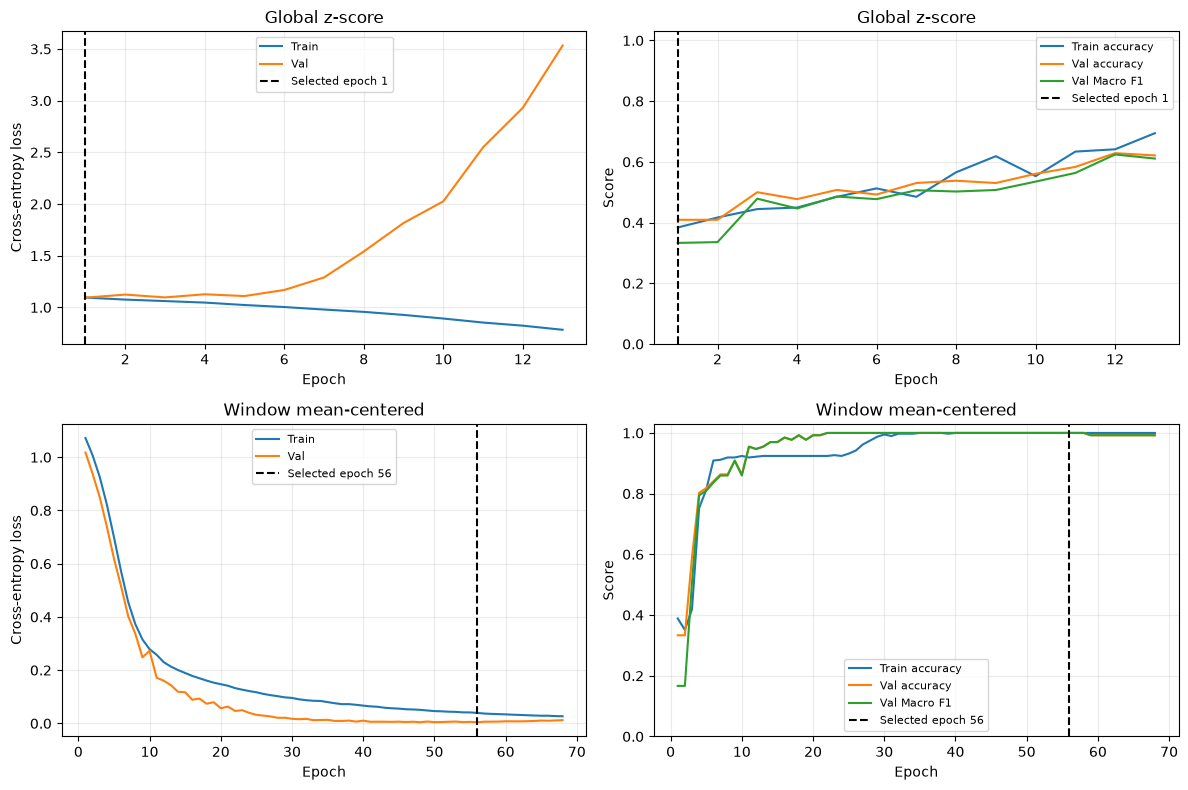

In [23]:
# 실행 셀 23
# 두 전처리 방식의 학습곡선
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row_index, (name, run_history, chosen_epoch) in enumerate([
    ("Global z-score", history, best_epoch),
    ("Window mean-centered", history_v2, summary_v2["best_epoch"]),
]):
    epochs = np.arange(1, len(run_history["train_loss"]) + 1)
    for key, label in [("train_loss", "Train"), ("val_loss", "Val")]:
        axes[row_index, 0].plot(epochs, run_history[key], label=label)
    for key, label in [("train_accuracy", "Train accuracy"),
                       ("val_accuracy", "Val accuracy"),
                       ("val_macro_f1", "Val Macro F1")]:
        axes[row_index, 1].plot(epochs, run_history[key], label=label)
    for column in range(2):
        ax = axes[row_index, column]
        ax.axvline(chosen_epoch, color="black", linestyle="--",
                   label=f"Selected epoch {chosen_epoch}")
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    axes[row_index, 0].set_ylabel("Cross-entropy loss")
    axes[row_index, 1].set_ylabel("Score")
    axes[row_index, 1].set_ylim(0, 1.03)
plt.tight_layout()
plt.show()


Window mean-centered Val Accuracy : 1.0000
Window mean-centered Val Macro F1 : 1.0000

Window mean-centered Classification Report:
                  precision    recall  f1-score   support

     PRE_DESCENT     1.0000    1.0000    1.0000        44
         DESCENT     1.0000    1.0000    1.0000        44
LANDING_RESPONSE     1.0000    1.0000    1.0000        44

        accuracy                         1.0000       132
       macro avg     1.0000    1.0000    1.0000       132
    weighted avg     1.0000    1.0000    1.0000       132



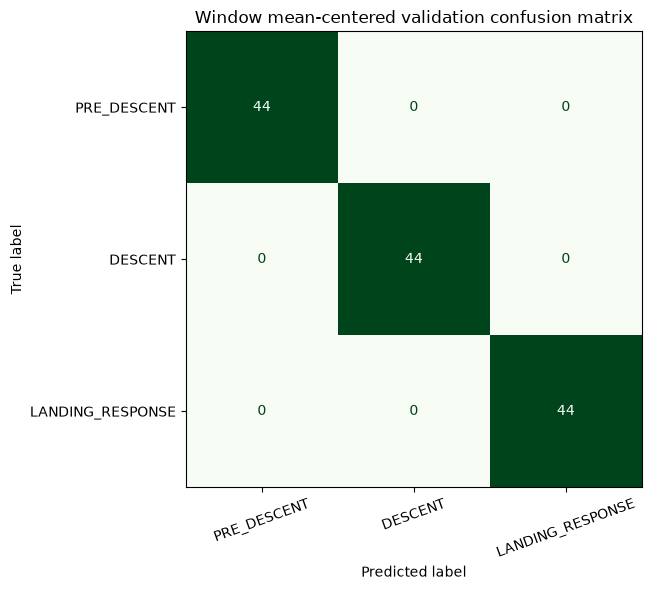

In [24]:
# 실행 셀 24
# Window mean-centered 최적 모델의 Val 성능 평가

model_v2.eval()

val_predictions_v2 = []
val_targets_v2 = []

with torch.no_grad():
    for X_batch, y_batch in val_loader_v2:
        X_batch = X_batch.to(device)

        logits = model_v2(X_batch)
        predictions = logits.argmax(dim=1)

        val_predictions_v2.extend(
            predictions.cpu().numpy()
        )
        val_targets_v2.extend(
            y_batch.numpy()
        )

val_accuracy_v2 = accuracy_score(
    val_targets_v2,
    val_predictions_v2,
)

val_macro_f1_v2 = f1_score(
    val_targets_v2,
    val_predictions_v2,
    average="macro",
)

confusion_matrix_v2 = confusion_matrix(
    val_targets_v2,
    val_predictions_v2,
)

print(f"Window mean-centered Val Accuracy : {val_accuracy_v2:.4f}")
print(f"Window mean-centered Val Macro F1 : {val_macro_f1_v2:.4f}")

print("\nWindow mean-centered Classification Report:")
print(
    classification_report(
        val_targets_v2,
        val_predictions_v2,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

cm_display_v2 = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_v2,
    display_labels=class_names,
)

fig, ax = plt.subplots(figsize=(7, 6))

cm_display_v2.plot(
    ax=ax,
    cmap="Greens",
    colorbar=False,
)

plt.title("Window mean-centered validation confusion matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [25]:
# 실행 셀 25
comparison = pd.DataFrame([
    {"preprocessing": "Global z-score", "best_epoch": best_epoch,
     "val_loss": best_val_loss, "accuracy": val_accuracy, "macro_f1": val_macro_f1},
    {"preprocessing": "Window mean-centered", "best_epoch": summary_v2["best_epoch"],
     "val_loss": summary_v2["best_val_loss"], "accuracy": val_accuracy_v2,
     "macro_f1": val_macro_f1_v2},
])
notebook_display(comparison.style.format({
    "val_loss": "{:.4f}", "accuracy": "{:.4f}", "macro_f1": "{:.4f}"}))


,preprocessing,best_epoch,val_loss,accuracy,macro_f1
0,Global z-score,1,1.0944,0.4091,0.3330
1,Window mean-centered,56,0.0041,1.0000,1.0000


In [26]:
# 실행 셀 26
# Global z-score과 Window mean-centered의 참가자별 성능 비교

val_results_v2 = (
    window_metadata.loc[val_mask]
    .copy()
    .reset_index(drop=True)
)

assert len(val_results_v2) == len(
    val_predictions_v2
)

val_results_v2["predicted_label"] = (
    val_predictions_v2
)

participant_metrics_v2 = []

for person, group in val_results_v2.groupby("person"):
    participant_metrics_v2.append({
        "person": person,
        "accuracy": accuracy_score(
            group["label"],
            group["predicted_label"],
        ),
        "macro_f1": f1_score(
            group["label"],
            group["predicted_label"],
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    })

participant_metrics_v2 = pd.DataFrame(
    participant_metrics_v2
)

participant_comparison = (
    participant_metrics[
        ["person", "accuracy", "macro_f1"]
    ]
    .merge(
        participant_metrics_v2,
        on="person",
        suffixes=("_zscore", "_centered"),
    )
)

print("onset_v3 | 하강 시작 1초 | 전처리 방식 비교")

notebook_display(
    participant_comparison.style.format({
        "accuracy_zscore": "{:.4f}",
        "macro_f1_zscore": "{:.4f}",
        "accuracy_centered": "{:.4f}",
        "macro_f1_centered": "{:.4f}",
    })
)

# Window mean-centered 참가자별 클래스 recall
participant_phase_rows_v2 = []

for person, person_group in val_results_v2.groupby("person"):
    for label, phase_name in PHASE_NAMES.items():
        phase_group = person_group.loc[
            person_group["label"] == label
        ]

        participant_phase_rows_v2.append({
            "person": person,
            "phase": phase_name,
            "recall": (
                phase_group["predicted_label"] == label
            ).mean(),
        })

recall_table_v2 = (
    pd.DataFrame(participant_phase_rows_v2)
    .pivot(
        index="person",
        columns="phase",
        values="recall",
    )
    .reindex(columns=[
        "PRE_DESCENT",
        "DESCENT",
        "LANDING_RESPONSE",
    ])
)

print("\nWindow mean-centered 참가자별 클래스 recall:")

notebook_display(
    recall_table_v2.style.format("{:.4f}")
)


onset_v3 | 하강 시작 1초 | 전처리 방식 비교


,person,accuracy_zscore,macro_f1_zscore,accuracy_centered,macro_f1_centered
0,P05,0.3333,0.1667,1.0000,1.0000
1,P06,0.4667,0.3662,1.0000,1.0000
2,P08,0.4222,0.3504,1.0000,1.0000



Window mean-centered 참가자별 클래스 recall:


phase,PRE_DESCENT,DESCENT,LANDING_RESPONSE
person,,,
P05,1.0000,1.0000,1.0000
P06,1.0000,1.0000,1.0000
P08,1.0000,1.0000,1.0000


윈도우별 평균 제거를 적용한 모델에서 더 높은 Val 성능을 보였습니다. 
단일 분할·seed에서 얻은 결과이므로, 다른 데이터에서도 같은 효과가 유지되는지는 확인하지 않았습니다.

## 7. Test Evaluation

저장한 모델에 Train 기준의 전처리를 적용해 Test를 평가했습니다. 평가 중에는 가중치를 수정하거나 모델을 다시 선택하지 않았습니다.

| 항목 | 내용 |
|---|---|
| 평가 대상 | Train/Val과 참가자가 겹치지 않는 3명 |
| 데이터 수 | 45 trial · 135개 윈도우 |
| 사용 모델 | 저장된 mean-centered checkpoint |
| 평가 성격 | 기존 Test 대상을 재사용한 탐색적 재평가 |

평가에 앞서 재학습 모델과 저장 모델의 가중치·편향 및 Train 표준편차가 일치하는지 확인하고, 저장 모델의 Val 성능을 다시 계산했습니다.

Test 대상은 이전 구간 설정 실험에서 이미 확인했으므로, 새로운 미사용 Test를 통한 최종 검증으로 해석하지 않았습니다.

In [27]:
# 실행 셀 27
# V3 centered 모델과 설정 저장

OUTPUT_DIR = PROJECT_DIR / "outputs" / "t6_phase_cnn_onset_v3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = OUTPUT_DIR / "onset_v3_centered_frozen.pt"

checkpoint = {
    "experiment": "onset_v3",
    "seed": SEED,
    "best_epoch": summary_v2["best_epoch"],
    "best_val_loss": summary_v2["best_val_loss"],
    "training_summary": dict(summary_v2),
    "model_version": "window_mean_centered",
    "window_start_rule": {
        "PRE_DESCENT": "S-1",
        "DESCENT": "S",
        "LANDING_RESPONSE": "E",
    },
    "window_seconds": WINDOW_SECONDS,
    "window_samples": WINDOW_SAMPLES,
    "class_names": class_names,
    "model_state_dict": copy.deepcopy(model_v2.state_dict()),
    "train_axis_std": centered_train_std.reshape(-1).copy(),
    "val_accuracy": float(val_accuracy_v2),
    "val_macro_f1": float(val_macro_f1_v2),
}

if checkpoint_path.exists():
    print("기존 저장 모델 유지:", checkpoint_path)
    print("이후 Test 평가는 기존 저장 모델을 사용합니다.")
else:
    torch.save(checkpoint, checkpoint_path)
    print("저장한 V3 모델:", checkpoint_path)
    print(f"Val Macro F1: {val_macro_f1_v2:.4f}")


기존 저장 모델 유지: <PROJECT_DIR>\outputs\t6_phase_cnn_onset_v3\onset_v3_centered_frozen.pt
이후 Test 평가는 기존 저장 모델을 사용합니다.


In [28]:
# 실행 셀 28
# Test 45 trial과 참가자 분리 확인

TEST_METADATA_PATH = (
    PROJECT_DIR
    / "outputs"
    / "t6_phase_test_preparation_v1"
    / "test_phase_preparation_45.csv"
)

assert checkpoint_path.is_file()
assert TEST_METADATA_PATH.is_file(), TEST_METADATA_PATH

test_metadata = pd.read_csv(TEST_METADATA_PATH)

assert len(test_metadata) == 45, len(test_metadata)
assert test_metadata["sample_id"].is_unique
assert test_metadata["split"].eq("Test").all()
assert test_metadata["person"].nunique() == 3

train_val_people = set(selected_metadata["person"])
test_people = set(test_metadata["person"])

assert train_val_people.isdisjoint(test_people), (
    "Train/Val과 Test에 같은 참가자가 있습니다."
)

print("Test trial:", len(test_metadata))
print("Test 참가자:", len(test_people))
print("\n참가자별 trial 수:")
notebook_display(
    test_metadata.groupby("person")["sample_id"]
    .nunique()
    .rename("trials")
)


Test trial: 45
Test 참가자: 3

참가자별 trial 수:


person
P04       15
P07    15
P09       15
Name: trials, dtype: int64

**기존 QC 승인 반영:** `P07__93cm__R1`

짧은 Z축 clipping이 있었지만 앞선 수동 검토에서 사용을 승인한 B등급 trial입니다. 아래 코드에서는 해당 승인 기록을 반영했습니다.

Test 경계표의 기록 시작 시각은 0초를 기준으로 했습니다.

In [29]:
# 실행 셀 29
# 기존 수동 승인 반영 및 Test raw 경로 확인

test_evaluation_metadata = test_metadata.copy()

approved_id = "P07__93cm__R1"
approved_mask = test_evaluation_metadata["sample_id"].eq(approved_id)

assert approved_mask.sum() == 1

other_holds = (
    test_evaluation_metadata["preparation_status"]
    .astype(str)
    .str.contains("hold", case=False, na=False)
    & ~approved_mask
)
assert not other_holds.any(), (
    "기존 승인 건 외에 보류 trial이 있습니다."
)

test_evaluation_metadata["manual_review_decision"] = ""
test_evaluation_metadata.loc[
    approved_mask, "manual_review_decision"
] = "pass_prior_waveform_review"

test_evaluation_metadata["record_begin_s"] = 0.0

test_evaluation_metadata["record_path"] = (
    test_evaluation_metadata.apply(
        lambda row: (
            RECORDS_DIR
            / row["person"]
            / "records"
            / row["record_folder"]
        ),
        axis=1,
    )
)

missing = test_evaluation_metadata.loc[
    ~test_evaluation_metadata["record_path"].map(Path.is_dir),
    ["sample_id", "record_path"],
]
assert missing.empty, missing

assert (
    test_evaluation_metadata["start_s"]
    - test_evaluation_metadata["record_begin_s"]
    >= WINDOW_SECONDS
).all()

assert (
    test_evaluation_metadata["end_s"]
    - test_evaluation_metadata["start_s"]
    >= WINDOW_SECONDS
).all()

assert (
    test_evaluation_metadata["record_end_s"]
    - test_evaluation_metadata["end_s"]
    >= WINDOW_SECONDS
).all()

print("평가 가능한 Test trial:", len(test_evaluation_metadata))
print("기존 검토 후 승인:", approved_id)
print("확인된 raw 폴더:", len(test_evaluation_metadata) - len(missing))


평가 가능한 Test trial: 45
기존 검토 후 승인: P07__93cm__R1
확인된 raw 폴더: 45


In [30]:
# 실행 셀 30
# V3 Test 입력 생성 및 예측

frozen = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

assert frozen["experiment"] == "onset_v3"
assert frozen["window_start_rule"]["DESCENT"] == "S"
assert frozen["model_version"] == "window_mean_centered"
assert frozen["window_samples"] == WINDOW_SAMPLES

test_windows = []
test_labels = []
test_window_records = []

for _, row in test_evaluation_metadata.iterrows():
    phase_windows = extract_phase_windows(row)

    for label in (0, 1, 2):
        test_windows.append(
            phase_windows[label].astype(np.float32)
        )
        test_labels.append(label)
        test_window_records.append({
            "sample_id": row["sample_id"],
            "person": row["person"],
            "label": label,
            "phase": PHASE_NAMES[label],
        })

X_test_raw = np.stack(test_windows)
y_test = np.asarray(test_labels, dtype=np.int64)
test_results = pd.DataFrame(test_window_records)

assert X_test_raw.shape == (135, 3, 1500)
assert test_results["sample_id"].nunique() == 45
assert test_results.groupby("sample_id")["label"].agg(list).apply(
    lambda labels: labels == [0, 1, 2]
).all()

train_std_test = np.asarray(
    frozen["train_axis_std"],
    dtype=np.float32,
).reshape(1, 3, 1)

assert np.isfinite(train_std_test).all()
assert (train_std_test > 0).all()

X_test = (
    X_test_raw
    - X_test_raw.mean(axis=2, keepdims=True)
) / train_std_test
X_test = X_test.astype(np.float32)

assert np.isfinite(X_test).all()

test_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_test),
        torch.from_numpy(y_test),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_model = PhaseCNN(num_classes=3).to(device)
test_model.load_state_dict(frozen["model_state_dict"])
test_model.eval()


PhaseCNN(
  (features): Sequential(
    (0): Conv1d(3, 16, kernel_size=(15,), stride=(1,), padding=(7,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Linear(in_features=32, out_features=3, bias=True)
)

In [31]:
# 실행 셀 31
# 저장 모델과 현재 재학습 모델의 동일성 확인
current_state = model_v2.state_dict()
frozen_state = frozen["model_state_dict"]
same_weights = set(current_state) == set(frozen_state) and all(
    torch.equal(current_state[key].detach().cpu(), frozen_state[key].detach().cpu())
    for key in current_state
)
same_scale = np.array_equal(
    centered_train_std.reshape(-1).astype(np.float32),
    train_std_test.reshape(-1),
)
print("재학습 모델과 저장 모델의 가중치 일치:", same_weights)
print("Train 축별 표준편차 일치:", same_scale)
print("Test checkpoint:", checkpoint_path)
print("checkpoint에 기록된 최적 epoch:", frozen.get("best_epoch", "기존 파일에 미기록"))

# 실제 Test 모델의 Val을 재평가: 가중치 업데이트 없음
X_val_frozen = ((X_val_raw - X_val_raw.mean(axis=2, keepdims=True))
                / train_std_test).astype(np.float32)
frozen_val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val_frozen), torch.from_numpy(y_val)),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
frozen_val_predictions = []
frozen_val_loss_sum = 0.0
with torch.no_grad():
    for inputs, targets in frozen_val_loader:
        scores = test_model(inputs.to(device))
        frozen_val_loss_sum += criterion(scores, targets.to(device)).item() * len(targets)
        frozen_val_predictions.extend(scores.argmax(dim=1).cpu().tolist())
frozen_val_summary = {
    "model_source": "Existing/saved checkpoint used for Test",
    "val_loss": frozen_val_loss_sum / len(y_val),
    "val_accuracy": accuracy_score(y_val, frozen_val_predictions),
    "val_macro_f1": f1_score(y_val, frozen_val_predictions,
                             labels=[0, 1, 2], average="macro", zero_division=0),
}
notebook_display(pd.DataFrame([frozen_val_summary]))
if not (same_weights and same_scale):
    print("현재 학습곡선은 재학습 모델의 기록입니다. Test 모델의 Val은 위 표를 사용하세요.")


재학습 모델과 저장 모델의 가중치 일치: True
Train 축별 표준편차 일치: True
Test checkpoint: <PROJECT_DIR>\outputs\t6_phase_cnn_onset_v3\onset_v3_centered_frozen.pt
checkpoint에 기록된 최적 epoch: 기존 파일에 미기록


,model_source,val_loss,val_accuracy,val_macro_f1
0,Existing/saved checkpoint used for Test,0.004146,1.0,1.0


In [32]:
# 실행 셀 32
test_predictions = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        predicted = test_model(
            X_batch.to(device)
        ).argmax(dim=1)

        test_predictions.extend(
            predicted.cpu().tolist()
        )

assert len(test_predictions) == 135

print("Test 입력 shape:", X_test.shape)
print("Test 예측 수:", len(test_predictions))


Test 입력 shape: (135, 3, 1500)
Test 예측 수: 135


V3 Test — 이전에 확인한 참가자의 탐색적 재평가
Accuracy: 0.9630
Macro F1: 0.9630
오답: 5 / 135

단계별 결과:
                  precision    recall  f1-score   support

     PRE_DESCENT     0.9556    0.9556    0.9556        45
         DESCENT     0.9778    0.9778    0.9778        45
LANDING_RESPONSE     0.9556    0.9556    0.9556        45

        accuracy                         0.9630       135
       macro avg     0.9630    0.9630    0.9630       135
    weighted avg     0.9630    0.9630    0.9630       135



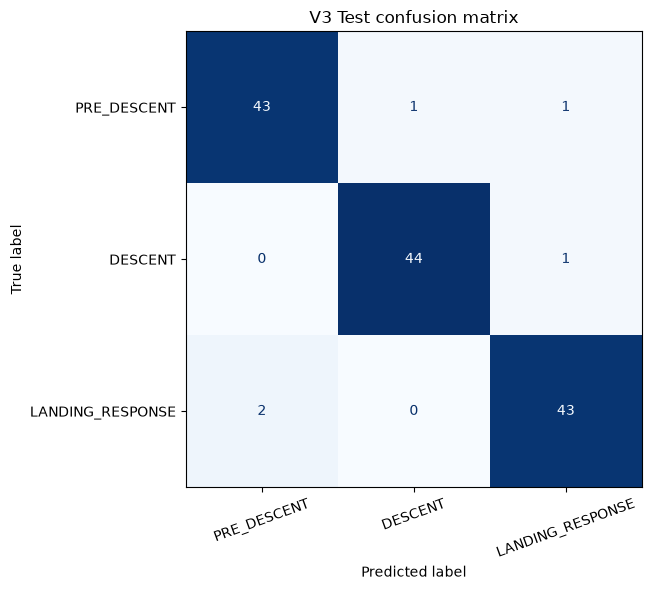

In [33]:
# 실행 셀 33
# V3 Test 성능 확인

test_results["predicted_label"] = test_predictions
test_results["predicted_phase"] = (
    test_results["predicted_label"].map(PHASE_NAMES)
)
test_results["correct"] = (
    test_results["label"] == test_results["predicted_label"]
)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
)

print("V3 Test — 이전에 확인한 참가자의 탐색적 재평가")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")
print(f"오답: {(~test_results['correct']).sum()} / 135")

print("\n단계별 결과:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0,
))

test_cm = confusion_matrix(
    y_test, test_predictions, labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=class_names,
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("V3 Test confusion matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Error Review

오분류된 5개 윈도우의 파형을 확인했습니다. 일부 PRE_DESCENT 구간에서 XYZ 값이 동시에 일정하게 유지되는 양상을 관찰했습니다.

아래에는 `P07__93cm__R3`의 파형과 동일값이 연속된 구간의 길이를 예시로 제시했습니다.

신호 고정 구간의 지속시간을 QC 항목으로 보완할 필요가 있다고 판단했습니다. 다만, 해당 양상이 오분류의 직접적인 원인인지는 검증하지 않았습니다.

오답 검토 후 Test 데이터를 제외하거나 모델을 재조정하지 않았습니다.

In [34]:
# 실행 셀 34
# Test 오답 목록

errors = test_results.loc[
    ~test_results["correct"]
].copy()

errors = errors.merge(
    test_evaluation_metadata[
        [
            "sample_id", "condition_cm", "repeat",
            "qc_grade", "start_s", "end_s",
        ]
    ],
    on="sample_id",
    how="left",
    validate="many_to_one",
)

print("오답 윈도우 수:", len(errors))

errors = errors.sort_values(
    ["person", "sample_id", "label"]
).reset_index(drop=True)

errors.insert(0, "error_no", range(1, len(errors) + 1))

notebook_display(
    errors[
        [
            "error_no", "person", "sample_id",
            "phase", "predicted_phase",
            "condition_cm", "repeat", "qc_grade",
            "start_s", "end_s",
        ]
    ]
)


오답 윈도우 수: 5


,error_no,person,sample_id,phase,predicted_phase,condition_cm,repeat,qc_grade,start_s,end_s
0,1,P04,P04__103cm__R1,LANDING_RESPONSE,PRE_DESCENT,103,1,A,2.472000,8.272000
1,2,P04,P04__103cm__R2,DESCENT,LANDING_RESPONSE,103,2,A,2.312667,8.112667
2,3,P04,P04__93cm__R1,PRE_DESCENT,LANDING_RESPONSE,93,1,A,2.366000,8.184000
3,4,P04,P04__93cm__R1,LANDING_RESPONSE,PRE_DESCENT,93,1,A,2.366000,8.184000
4,5,P07,P07__93cm__R3,PRE_DESCENT,DESCENT,93,3,A,2.482000,8.638667


,sample_id,person,label,phase,predicted_label,predicted_phase,correct
66,P07__93cm__R3,P07,0,PRE_DESCENT,1,DESCENT,False
67,P07__93cm__R3,P07,1,DESCENT,1,DESCENT,True
68,P07__93cm__R3,P07,2,LANDING_RESPONSE,2,LANDING_RESPONSE,True


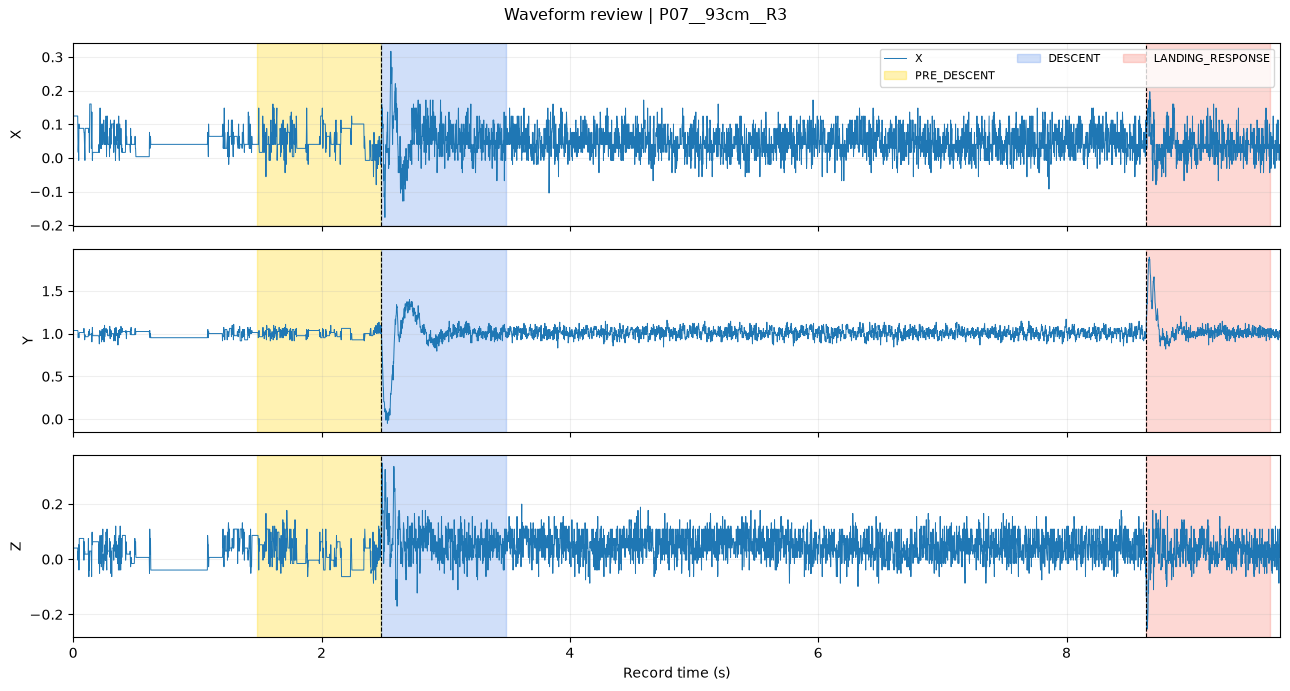

In [35]:
# 실행 셀 35
# 기존 검토 사례 — 번호 대신 trial ID로 고정
REVIEW_SAMPLE_ID = "P07__93cm__R3"
notebook_display(test_results.loc[test_results["sample_id"].eq(REVIEW_SAMPLE_ID)])
row = test_evaluation_metadata.loc[
    test_evaluation_metadata["sample_id"].eq(REVIEW_SAMPLE_ID)
].iloc[0]

xyz, fs, _ = load_t6_xyz(row["record_path"])

record_begin = float(row["record_begin_s"])
start_s = float(row["start_s"])
end_s = float(row["end_s"])
time_s = record_begin + np.arange(xyz.shape[1]) / fs

ranges = {
    "PRE_DESCENT": (start_s - 1.0, start_s),
    "DESCENT": (start_s, start_s + 1.0),
    "LANDING_RESPONSE": (end_s, end_s + 1.0),
}
phase_colors = {
    "PRE_DESCENT": "gold",
    "DESCENT": "cornflowerblue",
    "LANDING_RESPONSE": "salmon",
}

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)

for axis_index, (ax, axis_name) in enumerate(
    zip(axes, ("X", "Y", "Z"))
):
    ax.plot(
        time_s,
        xyz[axis_index],
        linewidth=0.7,
        label=axis_name,
    )

    for phase, (left, right) in ranges.items():
        ax.axvspan(
            left, right,
            color=phase_colors[phase],
            alpha=0.3,
            label=phase if axis_index == 0 else None,
        )

    ax.axvline(start_s, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(end_s, color="black", linestyle="--", linewidth=0.8)
    ax.set_ylabel(axis_name)
    ax.grid(alpha=0.2)

axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("Record time (s)")
axes[-1].set_xlim(time_s[0], time_s[-1])

fig.suptitle(f"Waveform review | {REVIEW_SAMPLE_ID}")
plt.tight_layout()
plt.show()


In [36]:
# 실행 셀 36
# 선택한 trial의 PRE 구간 동일값 연속 길이

sample_id = REVIEW_SAMPLE_ID
row = test_evaluation_metadata.loc[
    test_evaluation_metadata["sample_id"].eq(sample_id)
].iloc[0]

xyz, fs, _ = load_t6_xyz(row["record_path"])

pre_start_s = float(row["start_s"]) - 1.0
first = round((pre_start_s - row["record_begin_s"]) * fs)
pre_xyz = xyz[:, first:first + round(fs)]

# 이웃한 두 샘플에서 XYZ 세 축이 모두 정확히 같은지
same_xyz = np.all(pre_xyz[:, 1:] == pre_xyz[:, :-1], axis=0)

runs = []
run_start = None

for i, is_same in enumerate(np.r_[same_xyz, False]):
    if is_same and run_start is None:
        run_start = i
    elif not is_same and run_start is not None:
        sample_count = i - run_start + 1
        runs.append((
            pre_start_s + run_start / fs,
            sample_count,
            sample_count / fs,
        ))
        run_start = None

runs.sort(key=lambda item: item[1], reverse=True)

print("PRE 구간:", pre_start_s, "–", row["start_s"], "초")
print("XYZ 동시 동일값 최장 구간 (시작시각, 샘플 수, 지속시간):")
for item in runs[:5]:
    print(f"{item[0]:.4f} s | {item[1]} samples | {item[2]:.4f} s")


PRE 구간: 1.482000000000001 – 2.482000000000001 초
XYZ 동시 동일값 최장 구간 (시작시각, 샘플 수, 지속시간):
2.2447 s | 145 samples | 0.0967 s
1.8967 s | 127 samples | 0.0847 s
1.8007 s | 109 samples | 0.0727 s
2.1607 s | 109 samples | 0.0727 s
2.3527 s | 55 samples | 0.0367 s


## 결론과 한계

T6 가속도 기반 1D CNN으로 하강 전·하강 시작·착지 반응의 분류 가능성을 확인했습니다. 윈도우별 평균 제거를 적용한 모델에서 더 높은 Val 성능을 보였습니다.

| 항목 | 결과 및 해석 |
|---|---|
| Val Accuracy / Macro F1 | 1.0000 / 1.0000 |
| Test Accuracy / Macro F1 | 0.9630 / 0.9630 |
| 평가 한계 | 참가자 15명 · 단일 분할 · 기존 Test 대상 재사용 |
| 적용 범위 | 확정 경계 기반 구간 분류. 실시간 인식·임베디드 적용은 미검증 |

### 고찰

일부 오답 구간에서 XYZ 값이 동시에 일정하게 유지되는 양상을 확인했습니다.
초기 QC를 거쳤더라도 입력 윈도우에 품질 문제가 남을 수 있어, 전체 기록과 추출 구간을 함께 확인할 필요가 있었습니다.

향후에는 신호 고정 구간의 지속시간을 QC 기준에 포함하고, 정분류·오분류 사례 모두에 동일하게 적용할 필요가 있습니다. 다만 이번 분석에서는 해당 양상이 오분류의 원인인지, QC 보완이 성능 개선으로 이어지는지까지 검증하지 않았습니다.

### 수행 역할과 AI 활용

- **직접 수행:** 분석 목적과 구간 정의, QC·경계 수동 검토, 전처리 비교 실험 및 로컬 학습 실행, 파형 확인과 결과 해석
- **AI 활용:** 모델·전처리 설계 논의, 코드 작성·디버깅 지원, CNN 개념 학습, 문서 정리